# Wolfire et al. (2003) の中性原子ガスとの比較

太陽円 $R=8.5\,\mathrm{kpc}$、遮蔽柱密度 $N_{\rm cl}=10^{19}\,\mathrm{cm^{-2}}$ の標準モデルを使います。水素核数密度 $n_{\rm H}$ ごとに EQCLib の化学平衡組成を求め、全加熱率と全冷却率が等しくなる温度を探します。圧力は論文の §6.1 と同じく、電子を含む気相粒子の総数密度 $n_{\rm part}$ から $P_{\rm th}/k_{\rm B}=n_{\rm part}T$ とします。

論文の Figure 8 の実線を PDF の曲線から読み取って重ねます。二相共存圧力と枝上の温度・密度を数値で比べるときは Table 3 の掲載値を使います。 [Wolfire et al. (2003) §6.1・Table 1・3・4](https://arxiv.org/pdf/astro-ph/0207098#page=24) · [Figure 8](https://arxiv.org/pdf/astro-ph/0207098#page=86)

再計算は EQCLib のルートで `make -C test/wolfire2003 run` を実行し、このノートブックの全セルを実行します。Figure 8 の曲線は [抽出スクリプト](../test/wolfire2003/extract_wolfire2003_fig8.py) から再生成できます。Python 側では NumPy、SciPy、pandas、Matplotlib を使います。 [計算条件と出力](../test/README.md#wolfire-et-al-2003-との熱平衡曲線の比較) · [1995 年版の検証](PlotWolfire1995.ipynb)

## 入力条件

| 量 | Wolfire et al. (2003) の標準値 | EQCLib での設定 |
|---|---:|---|
| 遠紫外線強度 $G_0$ | 1.7 Habing | 入射強度を 1.7 Habing に設定 |
| H の一次宇宙線電離率 | $1.8\times10^{-17}\,\mathrm{s^{-1}}$ | 一次率の基準は同じ。整合版は H の二次電離を追加 |
| H の一次 EUV・軟 X 線電離率 | $1.6\times10^{-17}\,\mathrm{s^{-1}}$ | 総電離率を照合。一次率の分離とスペクトル伝播は論文独自 |
| 遮蔽柱密度 $N_{\rm cl}$ | $10^{19}\,\mathrm{cm^{-2}}$、$A_V=0.005$ mag | 全密度で同じ柱密度を使う。EQCLib のダスト減光では $A_V\simeq0.0053$ mag |
| 気相 C/H、O/H | $1.4\times10^{-4}$、$3.2\times10^{-4}$ | 同じ気相数比 |
| PAH | $n_{\rm PAH}/n_{\rm H}=6\times10^{-7}$、$\phi_{\rm PAH}=0.5$ | EQCLib のダスト表面反応と熱過程を使用 |

両方の EQCLib 計算で He/H は 0.1、H・He の再結合は Case B とし、気相 Si/H は Wolfire et al. (1995) Table 2 の密度依存式を使います。主比較は H₂ 化学を有効、CO 化学を無効にします。高密度での H₂ の影響を調べるため、整合版で H₂ も無効にした計算を加えます。論文は S・Mg・Fe も気相化学と低温冷却に含めます。 [Wolfire et al. (1995) §2.3.4・Table 2](https://public.websites.umich.edu/~monnier/Courses/2003Fall_AY403_Pages/wolfire95.pdf)

**EQCLib（電離・加熱率を整合）**では、論文の暖相 $n_{\rm H}=0.30\,\mathrm{cm^{-3}}$ と冷相 $n_{\rm H}=33\,\mathrm{cm^{-3}}$ に対応する電子分率 $x_e=0.0218,2.36\times10^{-4}$ を基準にします。EUV・軟 X 線による H の総電離率を §4.3 の $5.3,7.5\times10^{-17}\,\mathrm{s^{-1}}$ に合わせ、同じ倍率を He にも使います。EUV・軟 X 線と宇宙線の加熱率も Figure 10b の読み取り値にそれぞれ合わせます。倍率は基準点の間で $\log x_e$ に対して対数補間し、外側では端の倍率を使います。宇宙線による H の二次電離には Wolfire et al. (1995) 式 (A1) の 35 eV 電子の収率を使います。 [Wolfire et al. (2003) §4.3](https://arxiv.org/pdf/astro-ph/0207098#page=22) · [Figure 10b](https://arxiv.org/pdf/astro-ph/0207098#page=89)

**EQCLib（既定の電離・加熱率）**は同じ気相組成・外部条件で、ライブラリの率をそのまま使います。整合版の補正は比較用ドライバーだけに適用します。論文は EUV・軟 X 線スペクトルを伝播させ、PAH の荷電状態を計算します。EQCLib は上記の近似と既存のダスト表面反応および光電加熱を用います。 [Wolfire et al. (2003) §3.3、§4.3、§5、Table 1・4](https://arxiv.org/pdf/astro-ph/0207098)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.interpolate import CubicSpline, PchipInterpolator
from scipy.optimize import brentq

cwd = Path.cwd()
repo = next(
    (directory for directory in (cwd, *cwd.parents)
     if (directory / "src" / "ChemicalEquilibriumCooling.h").is_file()),
    None,
)
if repo is None:
    raise FileNotFoundError("EQCLib のリポジトリ内から実行してください。")

comparison_dir = repo / "test/wolfire2003"
result_path = repo / "test/out/wolfire2003/equilibrium.csv"
if not result_path.is_file():
    raise FileNotFoundError("EQCLib のルートで make -C test/wolfire2003 run を実行してください。")

results = pd.read_csv(result_path)
paper_curve = pd.read_csv(comparison_dir / "wolfire2003_fig8_standard.csv").sort_values("nH_cm3")
profile_fields = ["nH_cm3", "T_K", "P_over_k_K_cm3"]
for model, profile in results.groupby("model", sort=False):
    profile = profile.sort_values("nH_cm3")
    if not np.all(np.isfinite(profile[profile_fields]) & (profile[profile_fields] > 0)):
        raise ValueError(f"{model}: invalid equilibrium values")
    if not np.all(np.diff(profile["nH_cm3"]) > 0):
        raise ValueError(f"{model}: density values must be distinct")
    if len(profile) != 1001 or not np.isfinite(profile["residual"]).all() or profile["residual"].abs().max() >= 1e-9:
        raise ValueError(f"{model}: expected 1001 thermal roots with relative residual below 1e-9")

paper_pressures = {"Pmin": 1960.0, "Pgeom": 3070.0, "Pmax": 4810.0}
paper_points = pd.DataFrame(
    [("WNM", "Pmin", 0.209, 8310.0), ("WNM", "Pgeom", 0.349, 7860.0),
     ("WNM", "Pmax", 0.860, 5040.0), ("CNM", "Pmin", 6.91, 258.0),
     ("CNM", "Pgeom", 32.9, 85.0), ("CNM", "Pmax", 71.0, 61.6)],
    columns=["phase", "pressure_point", "nH_cm3", "T_K"],
)
paper_points["P_over_k_K_cm3"] = paper_points["pressure_point"].map(paper_pressures)
paper_warm_turn = 0.860
paper_cold_turn = 6.91

## 安定枝と二相共存の判定

熱平衡曲線の傾き $dP_{\rm th}/dn_{\rm H}$ が正なら等圧摂動に対して安定です。低密度の暖相（WNM）の上端は局所最大圧力 $P_{\max}$、高密度の冷相（CNM）の下端は局所最小圧力 $P_{\min}$ です。その間の圧力では、同じ圧力の WNM と CNM が存在できます。図の点は枝の端で、等圧摂動に対して限界安定です。中性原子相の転回点は $n_{\rm H}<100\,\mathrm{cm^{-3}}$ で探します。

各密度で $5$ K から $1.2\times10^4$ K までを対数温度で 96 分割し、加熱優勢から冷却優勢に移る解を確認します。二分法で熱収支残差 $|H-L|/\max(H,L)<10^{-9}$ まで求めます。密度格子は $10^{-2}$〜$10^3\,\mathrm{cm^{-3}}$、間隔は 0.005 dex です。

EQCLib の転回点は、密度格子の傾きが反転する区間で、$\log n_{\rm H}$ に対する $\log(P_{\rm th}/k_{\rm B})$ の三次スプラインの導関数をゼロにして求めます。代表圧力 $P_{\rm geom}=\sqrt{P_{\min}P_{\max}}$ は論文の式 (22) と同じ定義です。Table 3 の $P_{\rm geom}/k_{\rm B}$ には丸め後の 3070 を使います。 [Wolfire et al. (2003) §6.1](https://arxiv.org/pdf/astro-ph/0207098#page=24)

In [2]:
def measure_equilibrium(profile):
    profile = profile.sort_values("nH_cm3")
    density = np.log(profile["nH_cm3"].to_numpy())
    pressure = np.log(profile["P_over_k_K_cm3"].to_numpy())
    log_pressure = CubicSpline(density, pressure)
    log_temperature = PchipInterpolator(density, np.log(profile["T_K"]))
    slope = log_pressure.derivative()
    changes = np.flatnonzero(np.diff(np.sign(np.diff(pressure)))) + 1
    turning_points = []
    for index in changes:
        lo, hi = density[index - 1], density[index + 1]
        if slope(lo) * slope(hi) < 0:
            turning_points.append(brentq(slope, lo, hi, xtol=1e-12))
    turning_points = np.unique(np.round(turning_points, 12))
    diffuse_turning_points = turning_points[turning_points < np.log(100)]
    if len(diffuse_turning_points) != 2:
        raise ValueError(f"Expected a diffuse WNM maximum and CNM minimum, got {len(diffuse_turning_points)} extrema")
    warm_turn, cold_turn = diffuse_turning_points
    edges = np.r_[density[0], turning_points, density[-1]]
    segments = [(lo, hi, slope((lo + hi) / 2) > 0) for lo, hi in zip(edges[:-1], edges[1:])]
    if [segment[2] for segment in segments[:3]] != [True, False, True]:
        raise ValueError("The diffuse equilibrium curve does not have WNM/unstable/CNM ordering")
    return {
        "pressure": log_pressure,
        "temperature": log_temperature,
        "segments": segments,
        "diffuse_turning_points": (warm_turn, cold_turn),
        "molecular_fraction": PchipInterpolator(density, profile["x_H2"]),
        "Pmin": np.exp(log_pressure(cold_turn)),
        "Pmax": np.exp(log_pressure(warm_turn)),
    }


profiles = {model: measure_equilibrium(profile) for model, profile in results.groupby("model", sort=False)}


def model_pressure_points(profile):
    pmin, pmax = profile["Pmin"], profile["Pmax"]
    return {"Pmin": pmin, "Pgeom": np.sqrt(pmin * pmax), "Pmax": pmax}


pressure_summary = pd.DataFrame.from_dict(
    {"Wolfire (2003), Table 3": paper_pressures,
     **{model: model_pressure_points(profile) for model, profile in profiles.items()}},
    orient="index",
)
pressure_summary["Pmin / Wolfire"] = pressure_summary["Pmin"] / paper_pressures["Pmin"]
pressure_summary["Pmax / Wolfire"] = pressure_summary["Pmax"] / paper_pressures["Pmax"]
pressure_summary["Pmax / Pmin"] = pressure_summary["Pmax"] / pressure_summary["Pmin"]
display(pressure_summary.style.format({**dict.fromkeys(paper_pressures, "{:,.0f}"),
                                      **dict.fromkeys(pressure_summary.columns[3:], "{:.2f}")}))

,Pmin,Pgeom,Pmax,Pmin / Wolfire,Pmax / Wolfire,Pmax / Pmin
"Wolfire (2003), Table 3","1,960","3,070","4,810",1.00,1.00,2.45
eqclib,"3,574","7,119","14,179",1.82,2.95,3.97
eqclib_native_ionization,"3,300","6,367","12,283",1.68,2.55,3.72
eqclib_atomic,"3,543","7,089","14,184",1.81,2.95,4.00


上段の灰色は論文の二相共存圧力範囲です。下段は同じ密度での圧力比を示し、灰色は論文で傾きが負になる密度帯です。EQCLib の H₂ を含む計算では $n_{\rm H}\simeq150\,\mathrm{cm^{-3}}$ で水素核の H₂ 分率が $3\times10^{-4}$ から約 0.047 に急増し、圧力が局所的に約 0.3% 下がります。同じ放射条件の H₂ なしの計算ではこの変化が消え、拡散ガスの二相共存圧力はほぼ一致します。

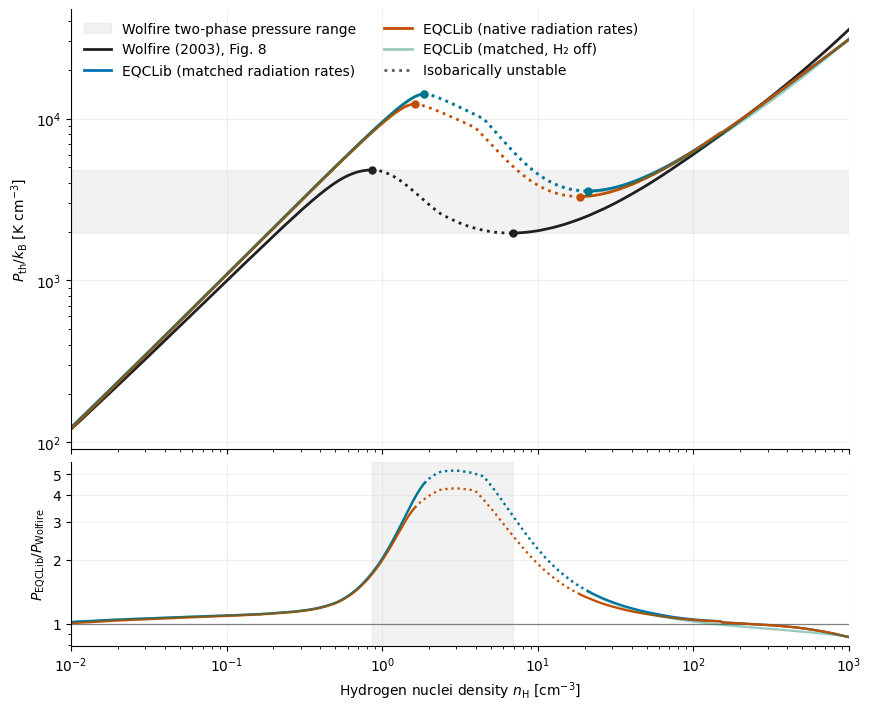

In [3]:
from itertools import cycle
from matplotlib.lines import Line2D
from matplotlib.ticker import NullFormatter

paper_color = "#202020"
colors = dict(zip(profiles, cycle(["#0072b2", "#c44e00", "#007b5e", "#8d4b9f"])))
model_names = {"eqclib": "EQCLib (matched radiation rates)",
               "eqclib_native_ionization": "EQCLib (native radiation rates)",
               "eqclib_atomic": "EQCLib (matched, H₂ off)"}
model_names_ja = {"eqclib": "EQCLib（電離・加熱率を整合）",
                  "eqclib_native_ionization": "EQCLib（既定の電離・加熱率）",
                  "eqclib_atomic": "EQCLib（電離・加熱率を整合、H₂ なし）"}
plot_style = {"axes.grid": True, "axes.axisbelow": True, "grid.alpha": 0.2,
              "axes.spines.top": False, "axes.spines.right": False,
              "legend.frameon": False, "font.size": 10}

paper_pressure = PchipInterpolator(np.log(paper_curve["nH_cm3"]),
                                  np.log(paper_curve["P_over_k_K_cm3"]), extrapolate=False)
paper_edges = np.log([paper_curve["nH_cm3"].min(), paper_warm_turn,
                      paper_cold_turn, paper_curve["nH_cm3"].max()])
paper_segments = list(zip(paper_edges[:-1], paper_edges[1:], (True, False, True)))


def draw_pressure_segments(ax, log_pressure, segments, color, label, opacity=1):
    for index, (lo, hi, stable) in enumerate(segments):
        log_density = np.linspace(lo, hi, 241)
        ax.plot(np.exp(log_density), np.exp(log_pressure(log_density)),
                color=color, linestyle="-" if stable else ":", linewidth=2, alpha=opacity,
                label=label if index == 0 else None)


with plt.rc_context(plot_style):
    fig, (ax, ratio_ax) = plt.subplots(2, 1, figsize=(8.6, 7.0), sharex=True,
                                       height_ratios=(2.4, 1), layout="constrained")
    ax.axhspan(paper_pressures["Pmin"], paper_pressures["Pmax"], color="0.7", alpha=0.16,
               label="Wolfire two-phase pressure range")
    draw_pressure_segments(ax, paper_pressure, paper_segments, paper_color, "Wolfire (2003), Fig. 8")
    ax.scatter([paper_warm_turn, paper_cold_turn], [paper_pressures["Pmax"], paper_pressures["Pmin"]],
               s=25, color=paper_color, zorder=4)

    ratio_ax.axhline(1, color="0.5", linewidth=0.9)
    ratio_ax.axvspan(paper_warm_turn, paper_cold_turn, color="0.7", alpha=0.16)
    for model, profile in profiles.items():
        color = colors[model]
        opacity = 0.4 if model == "eqclib_atomic" else 1
        draw_pressure_segments(ax, profile["pressure"], profile["segments"],
                               color, model_names.get(model, model), opacity)
        warm_turn, cold_turn = profile["diffuse_turning_points"]
        ax.scatter(np.exp([warm_turn, cold_turn]), [profile["Pmax"], profile["Pmin"]],
                   s=25, color=color, alpha=opacity, zorder=4)
        for lo, hi, stable in profile["segments"]:
            lo = max(lo, paper_edges[0])
            hi = min(hi, paper_edges[-1])
            if lo < hi:
                log_density = np.linspace(lo, hi, 241)
                ratio_ax.plot(np.exp(log_density),
                              np.exp(profile["pressure"](log_density) - paper_pressure(log_density)),
                              color=color, linestyle="-" if stable else ":", linewidth=1.65, alpha=opacity)

    ax.set(xscale="log", yscale="log", ylabel=r"$P_\mathrm{th}/k_\mathrm{B}$ [K cm$^{-3}$]")
    ratio_ax.set(yscale="log", xlabel=r"Hydrogen nuclei density $n_\mathrm{H}$ [cm$^{-3}$]",
                 ylabel=r"$P_\mathrm{EQCLib}/P_\mathrm{Wolfire}$", xlim=(0.01, 1000))
    ratio_ax.set_yticks([1, 2, 3, 4, 5], labels=["1", "2", "3", "4", "5"])
    ratio_ax.yaxis.set_minor_formatter(NullFormatter())
    handles, labels = ax.get_legend_handles_labels()
    handles.append(Line2D([0], [0], linestyle=":", color="0.35", linewidth=2))
    labels.append("Isobarically unstable")
    ax.legend(handles, labels, loc="upper left", ncols=2)
    plt.show()

## 安定枝上の密度と温度

まず Table 3 と同じ圧力で、それぞれの安定枝の $n_{\rm H}$ と $T$ を比較します。「—」は、その圧力が該当する EQCLib 安定枝の計算範囲外にあることを示します。掲載値の $P_{\rm geom}/k_{\rm B}=3070\,\mathrm{K\,cm^{-3}}$ では論文に両相があり、EQCLib では暖相が得られます。$P/k_{\rm B}=4000\,\mathrm{K\,cm^{-3}}$ では全モデルで両相が得られます。この点の論文値は Figure 8 の密度と Figure 10b の温度を PDF のベクトル曲線から対数補間した概数です。続いて EQCLib 自身の共存圧力の両端と幾何平均における両枝の状態を示します。

In [4]:
def branch_state(profile, phase, pressure):
    segments = profile["segments"][:1] if phase == "WNM" else profile["segments"][2:]
    target = np.log(pressure)
    pressure_at = profile["pressure"]
    for lo, hi, stable in segments:
        lower, upper = pressure_at([lo, hi])
        if stable and lower - 1e-10 <= target <= upper + 1e-10:
            clipped_target = np.clip(target, lower, upper)
            density = brentq(lambda log_density: pressure_at(log_density) - clipped_target, lo, hi)
            return np.exp(density), np.exp(profile["temperature"](density)), profile["molecular_fraction"](density)
    return np.nan, np.nan, np.nan


shared_pressure = 4000.0
from_figure = []
for phase, segment in (("WNM", paper_segments[0]), ("CNM", paper_segments[2])):
    lo, hi, _ = segment
    density = brentq(lambda x: paper_pressure(x) - np.log(shared_pressure), lo, hi)
    # Fig. 10b T is read at the density interpolated from Fig. 8.
    temperature = {"WNM": 7230.0, "CNM": 68.8}[phase]
    from_figure.append((phase, "Fig. 8 & 10b", np.exp(density), temperature, shared_pressure))

comparison_points = pd.concat([paper_points, pd.DataFrame(from_figure, columns=paper_points.columns)],
                              ignore_index=True)
comparison_points = comparison_points.sort_values(["P_over_k_K_cm3", "phase"], ascending=[True, False])
common = comparison_points.rename(columns={"nH_cm3": "Wolfire nH", "T_K": "Wolfire T"})
for model in ("eqclib", "eqclib_native_ionization"):
    profile = profiles[model]
    common[[f"{model} nH", f"{model} T"]] = [
        branch_state(profile, row.phase, row.P_over_k_K_cm3)[:2]
        for row in common.itertuples(index=False)
    ]

table_rows = []
for model, profile in profiles.items():
    for label, pressure in model_pressure_points(profile).items():
        for phase in ("WNM", "CNM"):
            nH, temperature, h2_fraction = branch_state(profile, phase, pressure)
            table_rows.append((model, label, pressure, phase, nH, temperature, h2_fraction))

model_points = pd.DataFrame(table_rows, columns=["model", "pressure_point", "P_over_k_K_cm3",
                                                "phase", "nH_cm3", "T_K", "f_H2"])
format_density = "{:.3g}"
format_temperature = "{:.4g}"
display(common.style.hide(axis="index").format(
    {"P_over_k_K_cm3": "{:,.0f}",
     **dict.fromkeys([column for column in common if column.endswith(" nH")], format_density),
      **dict.fromkeys([column for column in common if column.endswith(" T")], format_temperature)},
    na_rep="—",
))
display(model_points.style.hide(axis="index").format(
    {"P_over_k_K_cm3": "{:,.0f}", "nH_cm3": format_density, "T_K": format_temperature, "f_H2": "{:.2g}"}, na_rep="—",
))

phase,pressure_point,Wolfire nH,Wolfire T,P_over_k_K_cm3,eqclib nH,eqclib T,eqclib_native_ionization nH,eqclib_native_ionization T
WNM,Pmin,0.209,8310,"1,960",0.185,9341,0.185,9357
CNM,Pmin,6.91,258,"1,960",—,—,—,—
WNM,Pgeom,0.349,7860,"3,070",0.295,9214,0.297,9221
CNM,Pgeom,32.9,85,"3,070",—,—,—,—
WNM,Fig. 8 & 10b,0.496,7230,"4,000",0.39,9123,0.392,9119
CNM,Fig. 8 & 10b,52.8,68.8,"4,000",38.8,93.67,42.2,86.02
WNM,Pmax,0.86,5040,"4,810",0.474,9047,0.477,9032
CNM,Pmax,71,61.6,"4,810",60.5,72.25,62.4,70.01


model,pressure_point,P_over_k_K_cm3,phase,nH_cm3,T_K,f_H2
eqclib,Pmin,"3,574",WNM,0.347,9164,5.1e-09
eqclib,Pmin,"3,574",CNM,21,154.5,1.5e-05
eqclib,Pgeom,"7,119",WNM,0.723,8828,1.1e-08
eqclib,Pgeom,"7,119",CNM,121,53.42,0.00013
eqclib,Pmax,"14,179",WNM,1.87,6856,4.3e-08
eqclib,Pmax,"14,179",CNM,339,41.24,0.17
eqclib_native_ionization,Pmin,"3,300",WNM,0.32,9195,4.7e-09
eqclib_native_ionization,Pmin,"3,300",CNM,18.6,161.5,1.3e-05
eqclib_native_ionization,Pgeom,"6,367",WNM,0.645,8859,1e-08
eqclib_native_ionization,Pgeom,"6,367",CNM,102,56.73,9.6e-05


## 基準点での電離と加熱

論文の Figure 10b と同じ暖相・冷相の密度で $T$、$x_e$、H の総 EUV・軟 X 線電離率と加熱率を示します。論文の $\zeta_{\rm H,XR}$ は §4.3 の値で、図から読む他の値は概数です。整合版の倍率は論文の解の $x_e$ で合わせています。EQCLib の自己無撞着解の $x_e$ が変われば、ここに表示する電離率・加熱率も変わります。CSV の加熱率と冷却率は体積当たりの erg cm⁻³ s⁻¹、表の加熱率は各値を $n_{\rm H}$ で割った erg s⁻¹ H核⁻¹ です。 [Wolfire et al. (2003) §4.3](https://arxiv.org/pdf/astro-ph/0207098#page=22) · [Figure 10b](https://arxiv.org/pdf/astro-ph/0207098#page=89)

In [5]:
anchor_rows = [
    ("WNM", 0.30, "Wolfire (2003)", 8025, 0.0218, 5.3e-17, 1.629e-26, 2.39e-27, 1.84e-28),
    ("CNM", 33.0, "Wolfire (2003)", 84.8, 2.36e-4, 7.5e-17, 4.113e-26, 7.67e-28, 1.07e-28),
]
for phase, nH in (("WNM", 0.30), ("CNM", 33.0)):
    for model in ("eqclib", "eqclib_native_ionization"):
        profile = results[results["model"] == model].sort_values("nH_cm3")
        sample = [np.interp(np.log(nH), np.log(profile["nH_cm3"]), profile[field])
                  for field in ("T_K", "x_e", "zeta_H_X", "H_PE", "H_X", "H_CR")]
        temperature, xe, zeta_x, pe, xr, cr = sample
        anchor_rows.append((phase, nH, model, temperature, xe, zeta_x, pe / nH, xr / nH, cr / nH))

anchor_table = pd.DataFrame(anchor_rows, columns=["phase", "nH", "model", "T (K)", "xe", "zeta_H_X (s⁻¹)",
                                                "H_PE/nH", "H_X/nH", "H_CR/nH"])
anchor_table = anchor_table.sort_values("nH", kind="stable")
display(anchor_table.style.hide(axis="index").format({"nH": "{:.2g}", "T (K)": "{:.4g}",
    **dict.fromkeys(anchor_table.columns[4:], "{:.3g}")}))

phase,nH,model,T (K),xe,zeta_H_X (s⁻¹),H_PE/nH,H_X/nH,H_CR/nH
WNM,0.3,Wolfire (2003),8025,0.0218,5.3e-17,1.63e-26,2.39e-27,1.84e-28
WNM,0.3,eqclib,9210,0.027,5.12e-17,2.42e-26,2.48e-27,1.91e-28
WNM,0.3,eqclib_native_ionization,9217,0.0221,3.14e-17,2.1e-26,1.91e-27,6.41e-28
CNM,33,Wolfire (2003),84.8,0.000236,7.5e-17,4.11e-26,7.67e-28,1.07e-28
CNM,33,eqclib,104.9,0.000285,7.52e-17,4.35e-26,8.13e-28,1.1e-28
CNM,33,eqclib_native_ionization,100.5,0.000237,4.19e-17,4.09e-26,6.61e-28,2.05e-28


## 比較結果

EQCLib にも暖相・冷相の安定枝が現れます。整合版の暖相の上端は $n_{\rm H}=1.87\,\mathrm{cm^{-3}}$、冷相の下端は $21.0\,\mathrm{cm^{-3}}$ です。論文の $0.860$、$6.91\,\mathrm{cm^{-3}}$ と比べて、いずれも高密度側にあります。電離・加熱率の規格化で差の大きさは変わりますが、既定の率でも圧力範囲は高くなります。論文の $P_{\rm geom}$ で冷相が現れるかどうかの違いは、同じ外部条件でライブラリ間の冷相・暖相の分布を比較する際に効きます。

In [6]:
summary = []
for model, profile in profiles.items():
    pmin, pmax = profile["Pmin"], profile["Pmax"]
    overlap_min = max(pmin, paper_pressures["Pmin"])
    overlap_max = min(pmax, paper_pressures["Pmax"])
    overlap = (f"{overlap_min:,.0f}〜{overlap_max:,.0f} K cm⁻³"
               if overlap_min <= overlap_max else "共通する圧力域なし")
    summary.append(
        f"- **{model_names_ja.get(model, model)}** の二相共存圧力は {pmin:,.0f}〜{pmax:,.0f} K cm⁻³。"
        f"論文に対する下限と上限の比はそれぞれ {pmin / paper_pressures['Pmin']:.2f}、"
        f"{pmax / paper_pressures['Pmax']:.2f} で、共通範囲は {overlap}。"
    )
worst_residual = results["residual"].abs().max()
summary.append(f"- {len(results):,} 点の平衡解が得られました。全加熱率と全冷却率の相対残差の最大は {worst_residual:.2g} です。")
display(Markdown("\n".join(summary)))

- **EQCLib（電離・加熱率を整合）** の二相共存圧力は 3,574〜14,179 K cm⁻³。論文に対する下限と上限の比はそれぞれ 1.82、2.95 で、共通範囲は 3,574〜4,810 K cm⁻³。
- **EQCLib（既定の電離・加熱率）** の二相共存圧力は 3,300〜12,283 K cm⁻³。論文に対する下限と上限の比はそれぞれ 1.68、2.55 で、共通範囲は 3,300〜4,810 K cm⁻³。
- **EQCLib（電離・加熱率を整合、H₂ なし）** の二相共存圧力は 3,543〜14,184 K cm⁻³。論文に対する下限と上限の比はそれぞれ 1.81、2.95 で、共通範囲は 3,543〜4,810 K cm⁻³。
- 3,003 点の平衡解が得られました。全加熱率と全冷却率の相対残差の最大は 1e-09 です。